# 02 — Visualisation et comparaison des données

Ce notebook compare les fichiers avant/après nettoyage et visualise la répartition par domaine, priorité, note et avis.

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
OUTPUTS = ROOT / 'data' / 'outputs'
raw = pd.read_excel(OUTPUTS / 'entreprises_avant_nettoyage.xlsx')
clean = pd.read_excel(OUTPUTS / 'entreprises_apres_nettoyage.xlsx', sheet_name='Entreprises')
sns.set_theme(style='whitegrid')
print(raw.shape, clean.shape)

Brut combiné : (1760, 12) | Nettoyé combiné : (900, 15)
Historique brut : (1760, 12) | Historique nettoyé : (291, 15)


In [ ]:
comparaison = pd.DataFrame({
    'Étape': ['Avant nettoyage', 'Après nettoyage'],
    'Lignes': [len(raw), len(clean)],
    'Colonnes': [raw.shape[1], clean.shape[1]],
    'Doublons place_id': [raw.duplicated('place_id').sum(), 0],
})
comparaison

,Jeu,Lignes,Colonnes
0,Historique brut,1760,12
1,Historique nettoyé,291,15
2,Collecte combinée brute,1760,12
3,Collecte combinée nettoyée,900,15


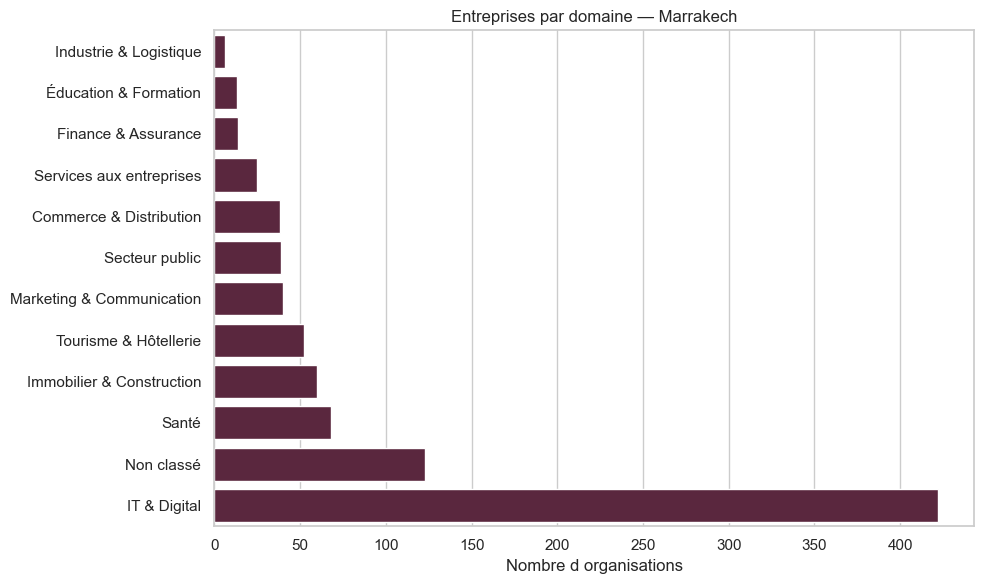

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ordre = clean['domaine'].value_counts().sort_values().index
sns.countplot(data=clean, y='domaine', order=ordre, color='#621E3E', ax=ax)
ax.set_title('Entreprises par domaine — Marrakech')
ax.set_xlabel('Nombre d organisations')
ax.set_ylabel('')
plt.tight_layout()

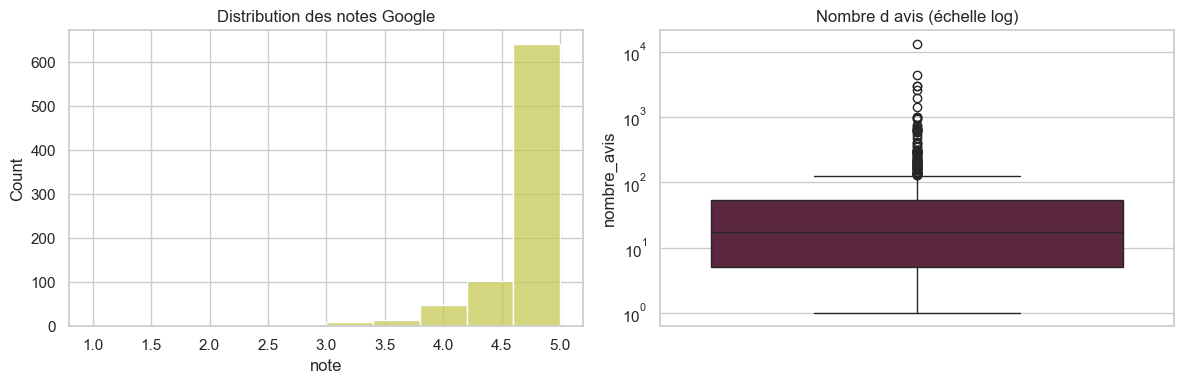

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(clean['note'].dropna(), bins=10, color='#C6C954', ax=axes[0])
axes[0].set_title('Distribution des notes Google')
sns.boxplot(y=clean['nombre_avis'].dropna(), color='#621E3E', ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Nombre d avis (échelle log)')
plt.tight_layout()

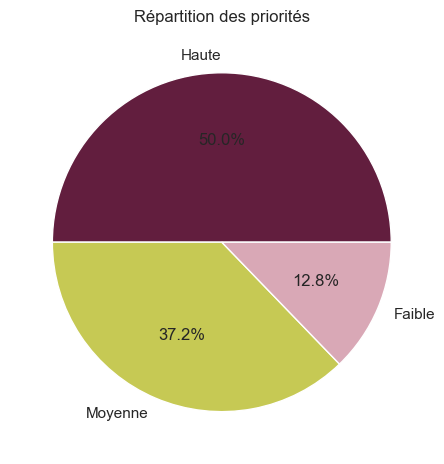

In [ ]:
priorites = clean['priorite'].value_counts()
priorites.plot.pie(autopct='%1.1f%%', colors=['#621E3E', '#C6C954', '#D9A8B6'])
plt.ylabel('')
plt.title('Répartition des priorités')
plt.tight_layout()

In [ ]:
rapport = {
  'brut': len(raw), 'propre': len(clean),
  'doublons_supprimes': raw.duplicated('place_id').sum(),
  'taux_conservation': round(len(clean) / max(len(raw), 1) * 100, 1),
  'entreprises_avec_site': int((clean['site_web'] != 'Non disponible').sum()),
}
rapport

{'brut': 1760,
 'propre': 900,
 'doublons_supprimes': np.int64(900),
 'taux_conservation': 51.1,
 'entreprises_avec_site': 694}